<a href="https://colab.research.google.com/github/HamzaEric/caltech101-transfer-learning/blob/main/Notebooks/Feature_Extraction_Pretrained_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os, json
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from pathlib import Path
import zipfile
import shutil
import random
import torch.nn.functional as F
import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
zip_path = '/content/drive/MyDrive/caltech-101.zip'
extract_path = '/content'


os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print(f"Successfully extracted all files to: {extract_path}")

Successfully extracted all files to: /content


In [3]:
!tar -xzf /content/caltech-101/101_ObjectCategories.tar.gz -C /content/caltech-101/

In [4]:
data_dir = '/content/caltech-101/101_ObjectCategories'

class_names = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
])

class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
idx_to_class = {idx: class_name for idx, class_name in enumerate(class_names)}

print(f"Total Classes Found: {len(class_names)}")
print(f"First 5 classes: {class_names[:5]}")

Total Classes Found: 102
First 5 classes: ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes']


In [5]:
source_dir = Path('/content/caltech-101/101_ObjectCategories')
output_dir = Path('/content/caltech-splits')

# Split ratios
train_ratio = 0.70
val_ratio = 0.15


random.seed(42)  # For reproducible splits

for class_folder in source_dir.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name

        # Get all valid image files
        images = [f for f in class_folder.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(n_total * train_ratio)
        n_val = int(n_total * val_ratio)

        train_imgs = images[:n_train]
        val_imgs = images[n_train:n_train + n_val]
        test_imgs = images[n_train + n_val:]

        # Create destination folders
        for split_name, split_imgs in [('train', train_imgs), ('val', val_imgs), ('test', test_imgs)]:
            split_class_dir = output_dir / split_name / class_name
            split_class_dir.mkdir(parents=True, exist_ok=True)

            for img_path in split_imgs:
                shutil.copy(img_path, split_class_dir / img_path.name)

print(f"Dataset successfully split and saved to: {output_dir}")

Dataset successfully split and saved to: /content/caltech-splits


In [6]:

DATA_ROOT = Path("/content/caltech-splits")
CKPT_DIR  = Path("/content/drive/MyDrive/checkpoints")
CKPT_PATH = CKPT_DIR / "resnet18_frozen_init.pth"
MAP_PATH  = CKPT_DIR / "class_to_idx.pth"

assert DATA_ROOT.exists(), f"Dataset not found at {DATA_ROOT}"
assert CKPT_PATH.exists(), f"Checkpoint not found at {CKPT_PATH} (run NB01 saves first)"
assert MAP_PATH.exists(), f"class_to_idx mapping not found at {MAP_PATH}"


class_to_idx = torch.load(MAP_PATH, weights_only = False)

# Build list of class names ordered by their index (0..K-1)
idx_to_class = {v:k for k, v in class_to_idx.items()}
class_names = [idx_to_class[i] for i in range(len(idx_to_class))]
num_classes = len(class_names)
print(f"[info] Classes ({num_classes}): {class_names}")

# --- Preprocessing pipeline
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
transform = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


train_ds = datasets.ImageFolder(DATA_ROOT / "train", transform=transform)
val_ds   = datasets.ImageFolder(DATA_ROOT / "val",   transform=transform)
test_ds  = datasets.ImageFolder(DATA_ROOT / "test",  transform=transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=0)

print(f"[info] Dataset sizes → train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze backbone
for p in model.parameters():
    p.requires_grad = False

# Replace head sized to our classes and load the saved state
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)

state_dict = torch.load(CKPT_PATH, map_location="cpu", weights_only = False)
model.load_state_dict(state_dict, strict=True)
model = model.to(device)
model.eval()

print("[info] Loaded frozen backbone + new head from checkpoint.")


[info] Classes (102): ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion', 'airplanes', 'anchor', 'ant', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill', 'dolphin', 'dragonfly', 'electric_guitar', 'elephant', 'emu', 'euphonium', 'ewer', 'ferry', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'gramophone', 'grand_piano', 'hawksbill', 'headphone', 'hedgehog', 'helicopter', 'ibis', 'inline_skate', 'joshua_tree', 'kangaroo', 'ketch', 'lamp', 'laptop', 'llama', 'lobster', 'lotus', 'mandolin', 'mayfly', 'menorah', 'metronome', 'minaret', 'nautilus', 'octopus', 'okapi', 'pagoda', 'panda', 'pigeon', 'pizza', 'platypus', 'pyramid', 'revolver', 'rhino', 'rooster', 'saxophone', 'schooner', 'scissors', 'scorpion', 'se

100%|██████████| 44.7M/44.7M [00:00<00:00, 127MB/s]


[info] Loaded frozen backbone + new head from checkpoint.


**Verify trainability and print a compact summary**

In [7]:
# Count params
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# List trainable tensors (should only be 'fc.*')
trainable_names = [n for n, p in model.named_parameters() if p.requires_grad]

print(f"[summary] Total parameters:     {total_params:,}")
print(f"[summary] Trainable parameters: {trainable_params:,}")
print("[summary] Trainable tensors:")
for n in trainable_names:
    print("  -", n)

# Safety check
assert all(n.startswith("fc.") for n in trainable_names), \
       "Unexpected trainable parameters outside the classifier head."

print("[check] Only the classifier head is trainable — setup is correct.")

[summary] Total parameters:     11,228,838
[summary] Trainable parameters: 52,326
[summary] Trainable tensors:
  - fc.weight
  - fc.bias
[check] Only the classifier head is trainable — setup is correct.


### **Loss Function, Optimizer, and Training Loop Design**

We now set up the **objective** and the **training loop** to learn only the **new classifier head** while keeping the pretrained backbone frozen.

**a) Criterion: Cross-Entropy Loss**
For a multi-class problem with one correct class per image, we use **cross-entropy loss**.  
If the model outputs logits $\mathbf{z} \in \mathbb{R}^K$ and the true class index is $y \in \{0,\dots,K-1\}$, the loss for one example is:
$$
\mathcal{L}(\mathbf{z}, y) = - \log \left( \frac{e^{z_y}}{\sum_{j=0}^{K-1} e^{z_j}} \right)
$$
Intuitively, this penalizes the model when the **softmax probability** assigned to the true class is low.

**b) Optimizer: Adam (only classifier parameters)**
We optimize **only** the classifier head parameters, e.g., `model.fc.parameters()`.  
The pretrained convolutional layers remain frozen (`requires_grad=False`) and therefore **do not receive gradients** or updates.

**c) Scheduler (Optional)**
A learning-rate scheduler (e.g., `StepLR`) gently reduces the learning rate as training progresses.  
This is optional for our short CPU-friendly runs, but helpful for demonstrating stable training practice.

**d) Training–Validation Loop**
We train for a **small number of epochs** (e.g., 5-10) to stay within a few minutes on CPU.  
Each epoch:
- **Train phase**: compute `train_loss` by averaging batch losses; update only the classifier head.
- **Validation phase**: compute `val_loss` and `val_acc` with `torch.no_grad()` (no gradient tracking); do **not** update weights.

In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)

use_scheduler = True
if use_scheduler:
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)
else:
    scheduler = None

print("[ok] Loss, optimizer (head-only), and scheduler are set.")


[ok] Loss, optimizer (head-only), and scheduler are set.


In [9]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()  # enables dropout/bn
    running_loss = 0.0
    total = 0

    for xb, yb in dataloader:
        xb, yb = xb.to(device), yb.to(device)

        # Forward
        logits = model(xb)
        loss = criterion(logits, yb)

        # Backward (only classifier head has requires_grad=True)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Accumulate
        batch_size = xb.size(0)
        running_loss += loss.item() * batch_size
        total += batch_size

    avg_loss = running_loss / max(total, 1)
    return avg_loss


@torch.no_grad()
def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    total = 0
    correct = 0

    for xb, yb in dataloader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)

        # Accumulate loss
        batch_size = xb.size(0)
        running_loss += loss.item() * batch_size
        total += batch_size

        # Compute accuracy
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()

    avg_loss = running_loss / max(total, 1)
    acc = correct / max(total, 1)
    return avg_loss, acc


In [14]:
import time

num_epochs = 50
history = {"train_loss": [], "val_loss": [], "val_acc": []}

patience = 5          # Number of epochs to wait for improvement before stopping
min_delta = 0.001     # Minimum change in validation loss to qualify as an improvement
best_val_loss = float('inf')
patience_counter = 0

print(f"[start] Training head-only for up to {num_epochs} epochs (No Scheduler)...")
start_time = time.time()

for epoch in range(1, num_epochs + 1):
    t0 = time.time()

    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    # --- SCHEDULER REMOVED FOR TESTING ---
    # if scheduler is not None:
    #     scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Fixed syntax error here
    dt = time.time() - t0

    print(f"Epoch {epoch:02d} | "
          f"train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | "
          f"val_acc={val_acc:.3f} | "
          f"epoch_time={dt:.1f}s")

    # --- Early Stopping Check ---
    if val_loss < (best_val_loss - min_delta):
        best_val_loss = val_loss
        patience_counter = 0
        # torch.save(model.state_dict(), 'best_model.pth')
    else:
        patience_counter += 1
        print(f"  [EarlyStopping] No improvement in val_loss for {patience_counter} epoch(s).")

        if patience_counter >= patience:
            print(f"[early stopping] Stopping early at epoch {epoch} due to no validation loss improvement.")
            break

# Fixed syntax error here
total_time = time.time() - start_time
print(f"[done] Finished training in {total_time:.1f}s")

[start] Training head-only for up to 50 epochs (No Scheduler)...
Epoch 01 | train_loss=0.2631 | val_loss=0.5458 | val_acc=0.847 | epoch_time=20.3s
Epoch 02 | train_loss=0.2641 | val_loss=0.5489 | val_acc=0.850 | epoch_time=20.3s
  [EarlyStopping] No improvement in val_loss for 1 epoch(s).
Epoch 03 | train_loss=0.2661 | val_loss=0.5461 | val_acc=0.851 | epoch_time=19.7s
  [EarlyStopping] No improvement in val_loss for 2 epoch(s).
Epoch 04 | train_loss=0.2663 | val_loss=0.5402 | val_acc=0.846 | epoch_time=20.8s
Epoch 05 | train_loss=0.2667 | val_loss=0.5398 | val_acc=0.850 | epoch_time=19.7s
  [EarlyStopping] No improvement in val_loss for 1 epoch(s).
Epoch 06 | train_loss=0.2588 | val_loss=0.5434 | val_acc=0.850 | epoch_time=20.8s
  [EarlyStopping] No improvement in val_loss for 2 epoch(s).
Epoch 07 | train_loss=0.2626 | val_loss=0.5385 | val_acc=0.851 | epoch_time=19.6s
Epoch 08 | train_loss=0.2597 | val_loss=0.5422 | val_acc=0.848 | epoch_time=20.8s
  [EarlyStopping] No improvement in

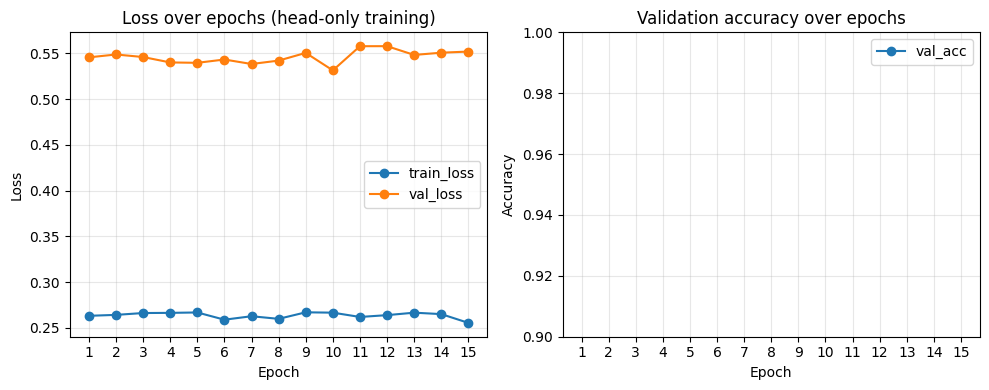

In [15]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 4))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="train_loss")
plt.plot(epochs, history["val_loss"], marker="o", label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over epochs (head-only training)")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(epochs, history["val_acc"], marker="o", label="val_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation accuracy over epochs")
plt.xticks(epochs)
plt.ylim(0.9, 1)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

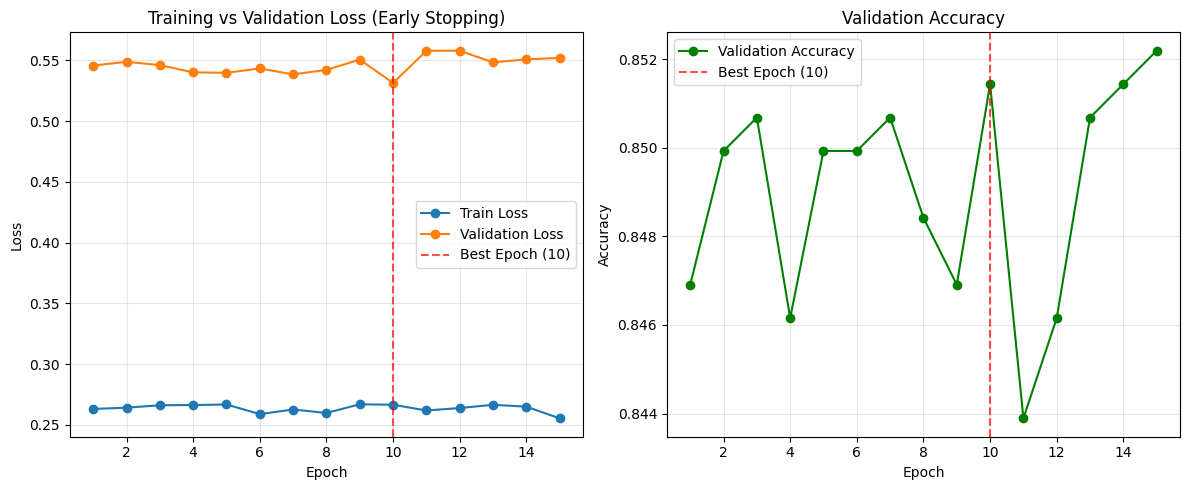

In [16]:
actual_epochs = len(history["train_loss"])
epochs = range(1, actual_epochs + 1)

# Find the exact epoch where validation loss was lowest
best_epoch = np.argmin(history["val_loss"]) + 1
best_val_loss = np.min(history["val_loss"])

plt.figure(figsize=(12, 5))

# 1. Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker='o', label='Train Loss')
plt.plot(epochs, history["val_loss"], marker='o', label='Validation Loss')
# Add a vertical line to show the best epoch
plt.axvline(x=best_epoch, color='red', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch})')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss (Early Stopping)")
plt.legend()
plt.grid(True, alpha=0.3)

# 2. Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(epochs, history["val_acc"], marker='o', color='green', label='Validation Accuracy')
plt.axvline(x=best_epoch, color='red', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch})')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

After training the classifier head, we now evaluate its performance on the **held-out test set**.  
Our goal is to understand not only the **overall accuracy**, but also how performance varies **per class**, and which classes tend to be **confused** with one another.

We will compute:
- **Overall accuracy** — proportion of correctly classified test images.
- **Per-class precision, recall, and F1** — these give a richer view than accuracy alone:
  - Precision (for a class $c$): $ \text{Prec}_c = \frac{\text{TP}_c}{\text{TP}_c + \text{FP}_c} $
  - Recall (for a class $c$): $ \text{Rec}_c = \frac{\text{TP}_c}{\text{TP}_c + \text{FN}_c} $
  - F1 (for a class $c$): $ \text{F1}_c = \frac{2 \cdot \text{Prec}_c \cdot \text{Rec}_c}{\text{Prec}_c + \text{Rec}_c} $
- A **confusion matrix heatmap** — this visualizes how predictions distribute across classes for each true label.

**Run inference and collect predictions**

In [20]:
model.eval()

y_true, y_pred, y_prob = [], [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)
        probs = torch.softmax(logits, dim=1)

        preds = torch.argmax(probs, dim=1).cpu().numpy()
        y_pred.extend(preds.tolist())
        y_true.extend(yb.numpy().tolist())
        y_prob.extend(probs.cpu().numpy().tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

test_acc = accuracy_score(y_true, y_pred)
print(f"[test] Overall accuracy: {test_acc:.4f}")

[test] Overall accuracy: 0.8458


**Per-class precision/recall/F1 and macro/micro averages**

In [21]:
from sklearn.metrics import classification_report

# Build a label list in the correct index order for the report
target_names = [class_names[i] for i in range(len(class_names))]

report = classification_report(
    y_true, y_pred, target_names=target_names, digits=3, zero_division=0
)
print(report)

                   precision    recall  f1-score   support

BACKGROUND_Google      0.575     0.704     0.633        71
            Faces      0.905     0.864     0.884        66
       Faces_easy      0.870     0.909     0.889        66
         Leopards      0.882     1.000     0.938        30
       Motorbikes      0.960     0.983     0.971       121
        accordion      0.900     1.000     0.947         9
        airplanes      0.937     0.992     0.964       120
           anchor      0.714     0.714     0.714         7
              ant      0.667     0.857     0.750         7
           barrel      0.750     0.750     0.750         8
             bass      0.833     0.556     0.667         9
           beaver      0.700     0.875     0.778         8
        binocular      0.800     0.667     0.727         6
           bonsai      0.818     0.900     0.857        20
            brain      0.875     0.875     0.875        16
     brontosaurus      0.667     0.286     0.400       

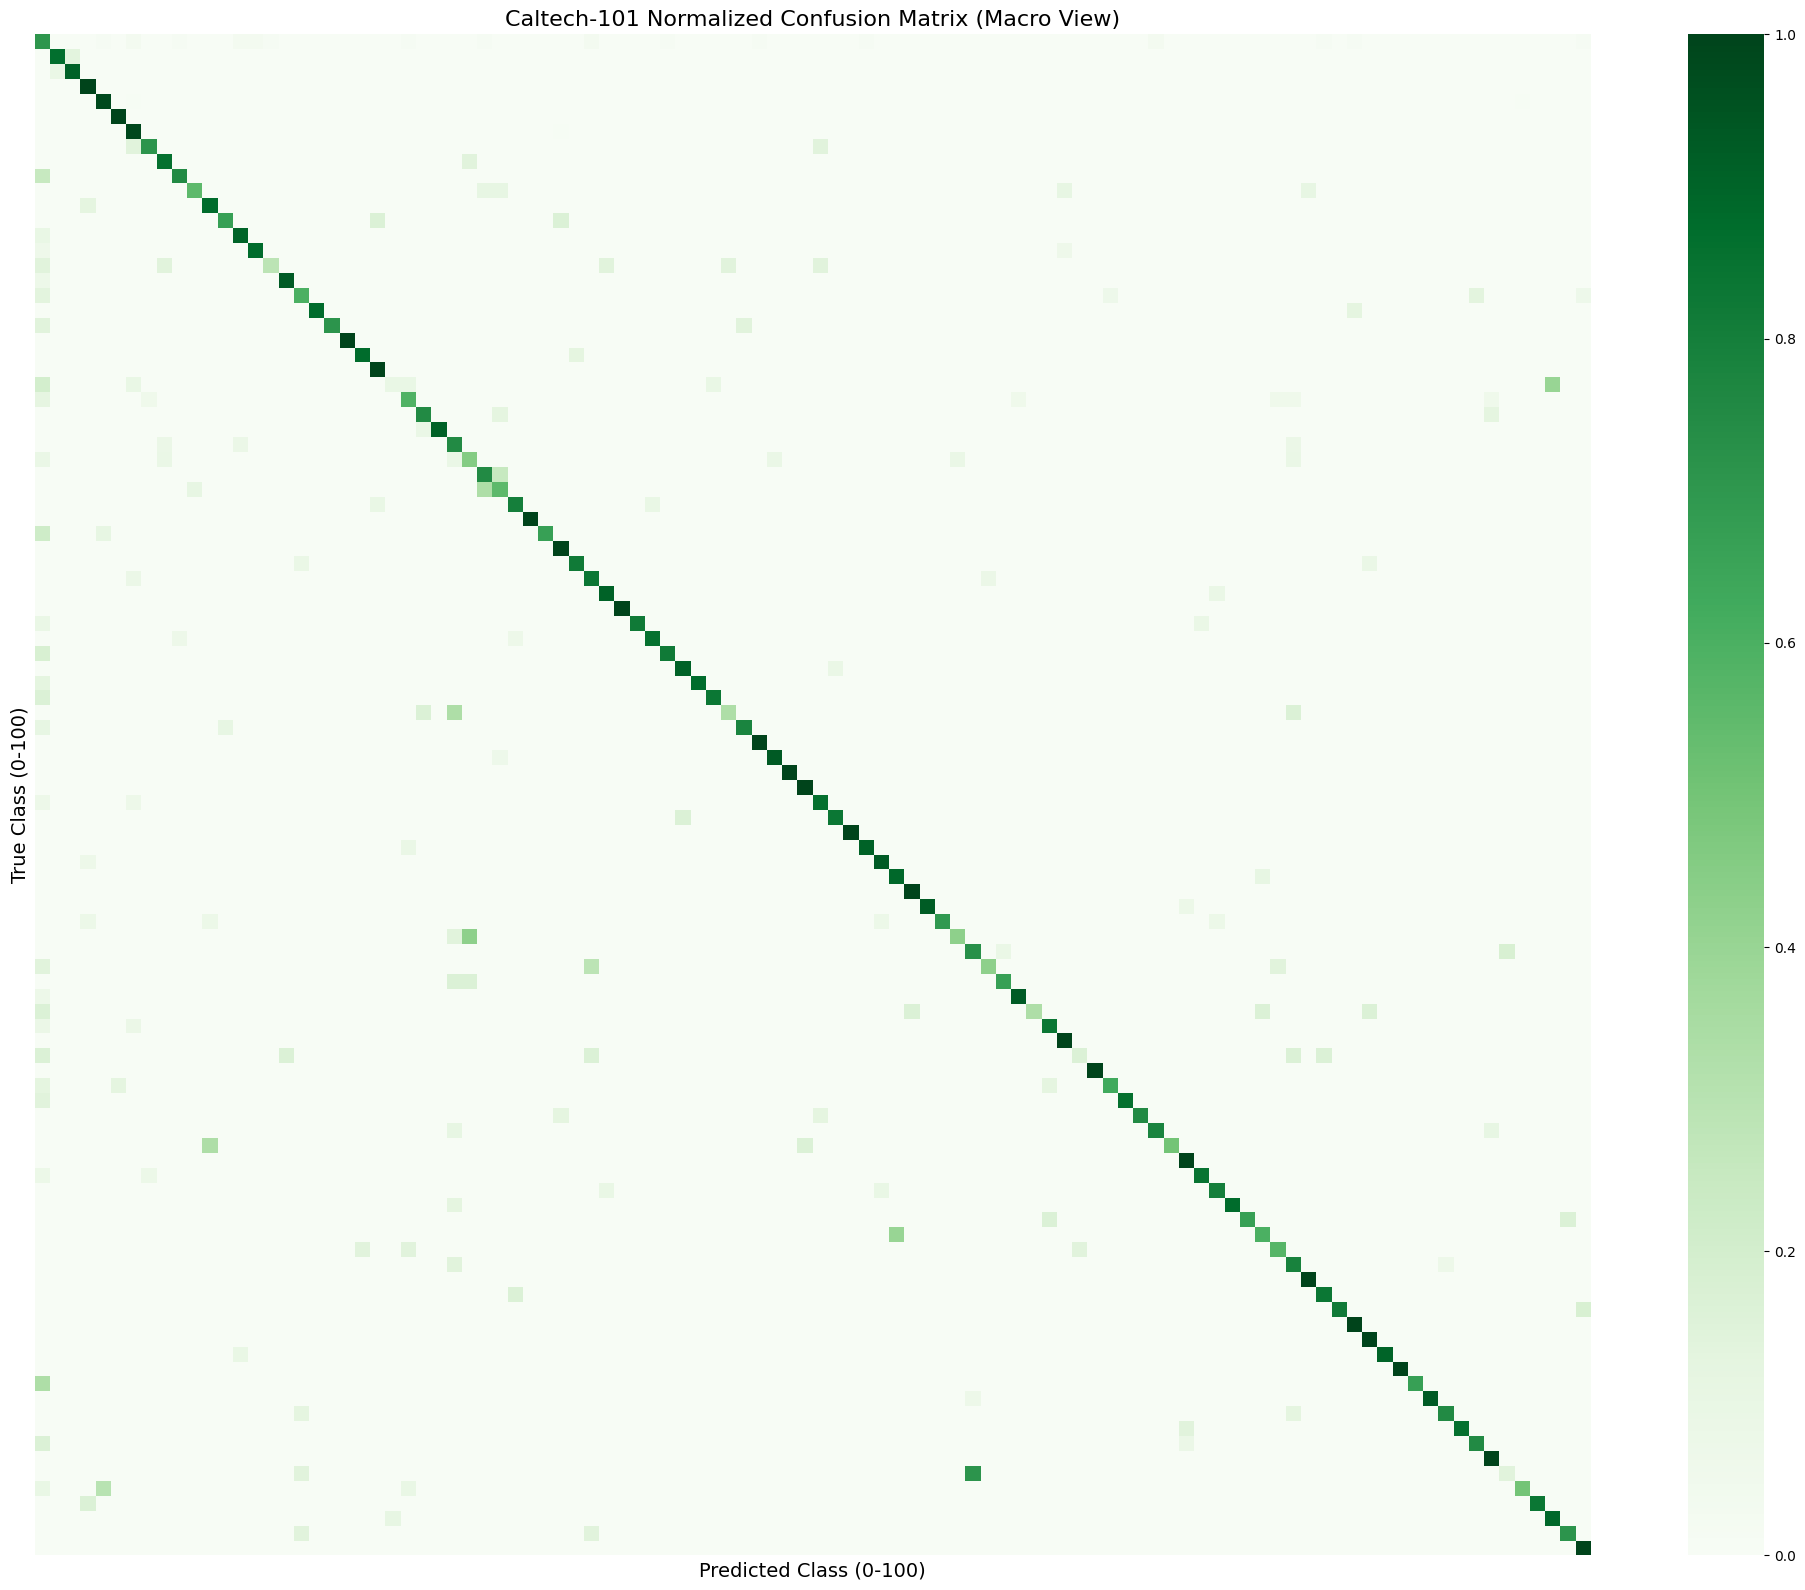

In [23]:
fig, ax = plt.subplots(figsize=(20, 16))

# Plot the row-normalized matrix without tick labels
sns.heatmap(cm_norm, annot=False, cmap="Greens", vmin=0.0, vmax=1.0,
            xticklabels=False, yticklabels=False, ax=ax)

ax.set_title("Caltech-101 Normalized Confusion Matrix (Macro View)", fontsize=16)
ax.set_xlabel("Predicted Class (0-100)", fontsize=14)
ax.set_ylabel("True Class (0-100)", fontsize=14)

plt.tight_layout()
plt.show()

In [24]:
cm_offdiag = cm_norm.copy()
np.fill_diagonal(cm_offdiag, 0.0)

# Get top-K confused pairs
K = 5
pairs = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j:
            pairs.append((cm_offdiag[i, j], i, j))
pairs.sort(reverse=True)
top_pairs = pairs[:K]

print("[insight] Top confused class pairs (normalized rates):")
for val, i, j in top_pairs:
    print(f"  True='{class_names[i]}' → Pred='{class_names[j]}' : {val:.3f}")

[insight] Top confused class pairs (normalized rates):
  True='water_lilly' → Pred='lotus' : 0.714
  True='lobster' → Pred='crayfish' : 0.429
  True='schooner' → Pred='ketch' : 0.400
  True='chair' → Pred='windsor_chair' : 0.400
  True='strawberry' → Pred='BACKGROUND_Google' : 0.333


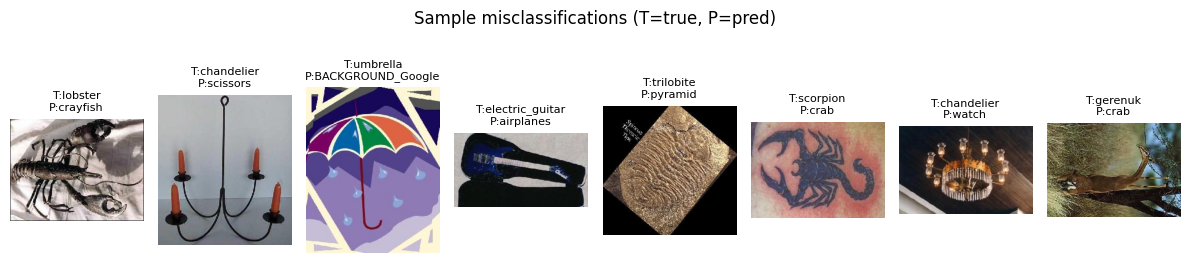

In [29]:

test_paths = []
for paths, _ in [( [p for p,_ in test_loader.dataset.samples], test_loader.dataset.targets )]:
    test_paths = paths


if not test_paths:
    test_paths = [p for p, _ in test_loader.dataset.samples]

mis_idx = np.where(y_true != y_pred)[0]
k = min(8, len(mis_idx))
if k > 0:
    sel = np.random.choice(mis_idx, size=k, replace=False)
    plt.figure(figsize=(12, 3))
    for t, idx in enumerate(sel):
        img_path = test_paths[idx]
        img = Image.open(img_path).convert("RGB")

        plt.subplot(1, k, t+1)
        plt.imshow(img)
        true_lbl = class_names[y_true[idx]]
        pred_lbl = class_names[y_pred[idx]]
        plt.title(f"T:{true_lbl}\nP:{pred_lbl}", fontsize=8)
        plt.axis("off")
    plt.suptitle("Sample misclassifications (T=true, P=pred)", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("[info] No misclassifications in sampled set (or very small test set).")


**How do we read these results?**

 - **Overall accuracy** provides a quick snapshot of performance, but it may hide class imbalances.  
 - **Per-class precision/recall/F1** reveal which categories are easier or harder.  
   - Low **recall** for a class means many of its images are missed (false negatives).  
   - Low **precision** for a class means many predictions for that class are incorrect (false positives).
 - The **confusion matrix** highlights systematic mistakes. If two classes are often confused with each other, it could be due to:
   - Visual similarity (e.g., similar textures or shapes),  
   - Background clutter or pose variation,  
   - Limited examples for the rarer class in our subset.

### **Visualizing Predictions and Model Confidence**

To build intuition about what our classifier head has learned, we will **visualize predictions on a few test images**.  
For each image, we will display the **true label**, the **predicted label**, and the model’s **confidence** (the highest softmax probability).

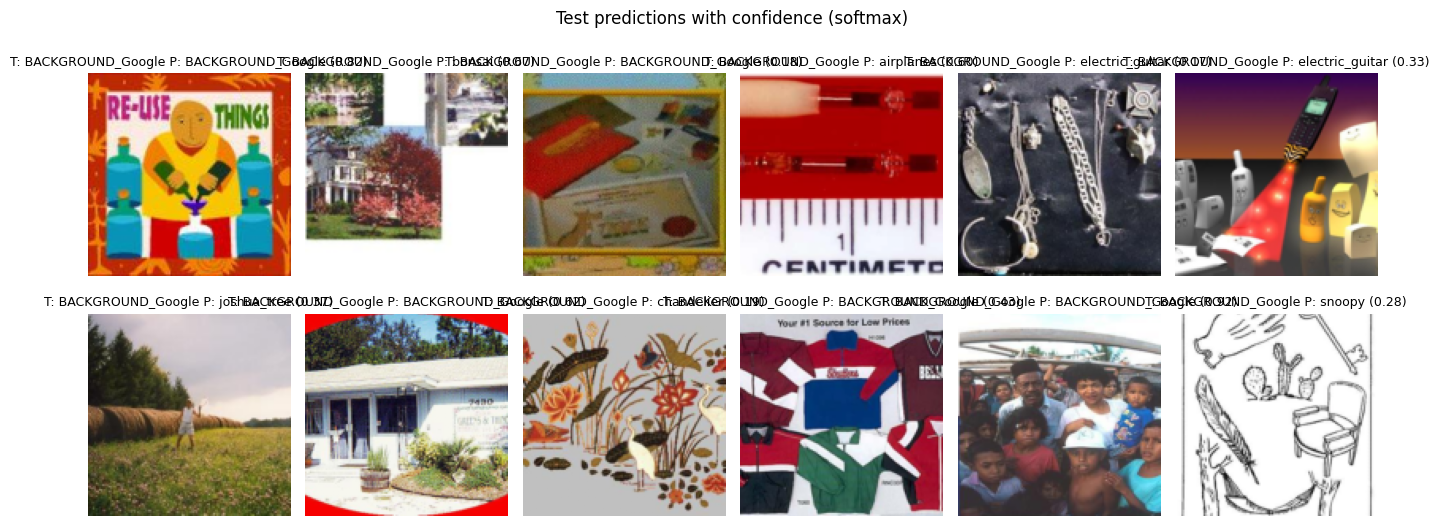

In [30]:
def unnormalize(img_tensor, mean, std):
    img = img_tensor.clone()
    for c, (m, s) in enumerate(zip(mean, std)):
        img[c] = img[c] * s + m
    return img.clamp(0, 1)

# Get one batch from the test loader
model.eval()
xb, yb = next(iter(test_loader))
xb_dev = xb.to(device)

with torch.no_grad():
    logits = model(xb_dev)
    probs = F.softmax(logits, dim=1).cpu()

pred_idx = probs.argmax(dim=1).numpy()
true_idx = yb.numpy()
conf = probs.max(dim=1).values.numpy()

# Pick up to 12 examples for a compact grid
k = min(12, xb.size(0))
cols = 6
rows = int(np.ceil(k / cols))

plt.figure(figsize=(cols * 2.2, rows * 2.8))

for i in range(k):
    img_disp = unnormalize(xb[i], IMAGENET_MEAN, IMAGENET_STD).permute(1, 2, 0).numpy()
    t_lbl = class_names[true_idx[i]]
    p_lbl = class_names[pred_idx[i]]
    cval = conf[i]

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img_disp)
    title = f"T: {t_lbl} P: {p_lbl} ({cval:.2f})"
    plt.title(title, fontsize=9)
    plt.axis("off")

plt.suptitle("Test predictions with confidence (softmax)", fontsize=12)
plt.tight_layout()
plt.show()


In [32]:

save_dir = Path("/content/drive/MyDrive/checkpoints")
save_dir.mkdir(parents=True, exist_ok=True)

model_path = save_dir / "resnet18_feature_extraction.pth"
torch.save(model.state_dict(), model_path)

logs = {
    "train_loss": history["train_loss"],
    "val_loss": history["val_loss"],
    "val_acc": history["val_acc"]
}

with open(save_dir / "training_logs_feature_extraction.json", "w") as f:
    json.dump(logs, f, indent=4)

print(f"[done] Saved model to: {model_path}")
print(f"[done] Saved training logs to: {save_dir/'training_logs_feature_extraction.json'}")


[done] Saved model to: /content/drive/MyDrive/checkpoints/resnet18_feature_extraction.pth
[done] Saved training logs to: /content/drive/MyDrive/checkpoints/training_logs_feature_extraction.json
